# 🤖 MAHA JAL KHOJ: Machine Learning Model Architecture & Evaluation
## Part 2: Spatially-Weighted Dual-Head XGBoost Forecasting & Multi-Metric Assessment

### 📌 Architecture Summary & High-Resolution Diagram
This notebook documents the machine learning engine designed to predict groundwater depth and detect multi-tier hydrogeological risk alerts across Maharashtra.

The architecture employs an **Inverse Spatial Density Balancing Layer** to eliminate clustered sampling bias between dense monitoring districts (e.g., Sangli with 92 stations) and sparse districts (e.g., Dhule with 4 stations), feeding a **Dual-Head XGBoost Core Engine** (`XGBRegressor` + `XGBClassifier`) coupled with a **10-Month Recursive Seasonal Projection Module**.

---

### 🏗️ ML Model Architecture Diagram
The high-resolution architecture diagram is saved directly in this folder as `ml_model_architecture.png`:

![Maha Jal Khoj Dual-Head ML Model Architecture](ml_model_architecture.png)


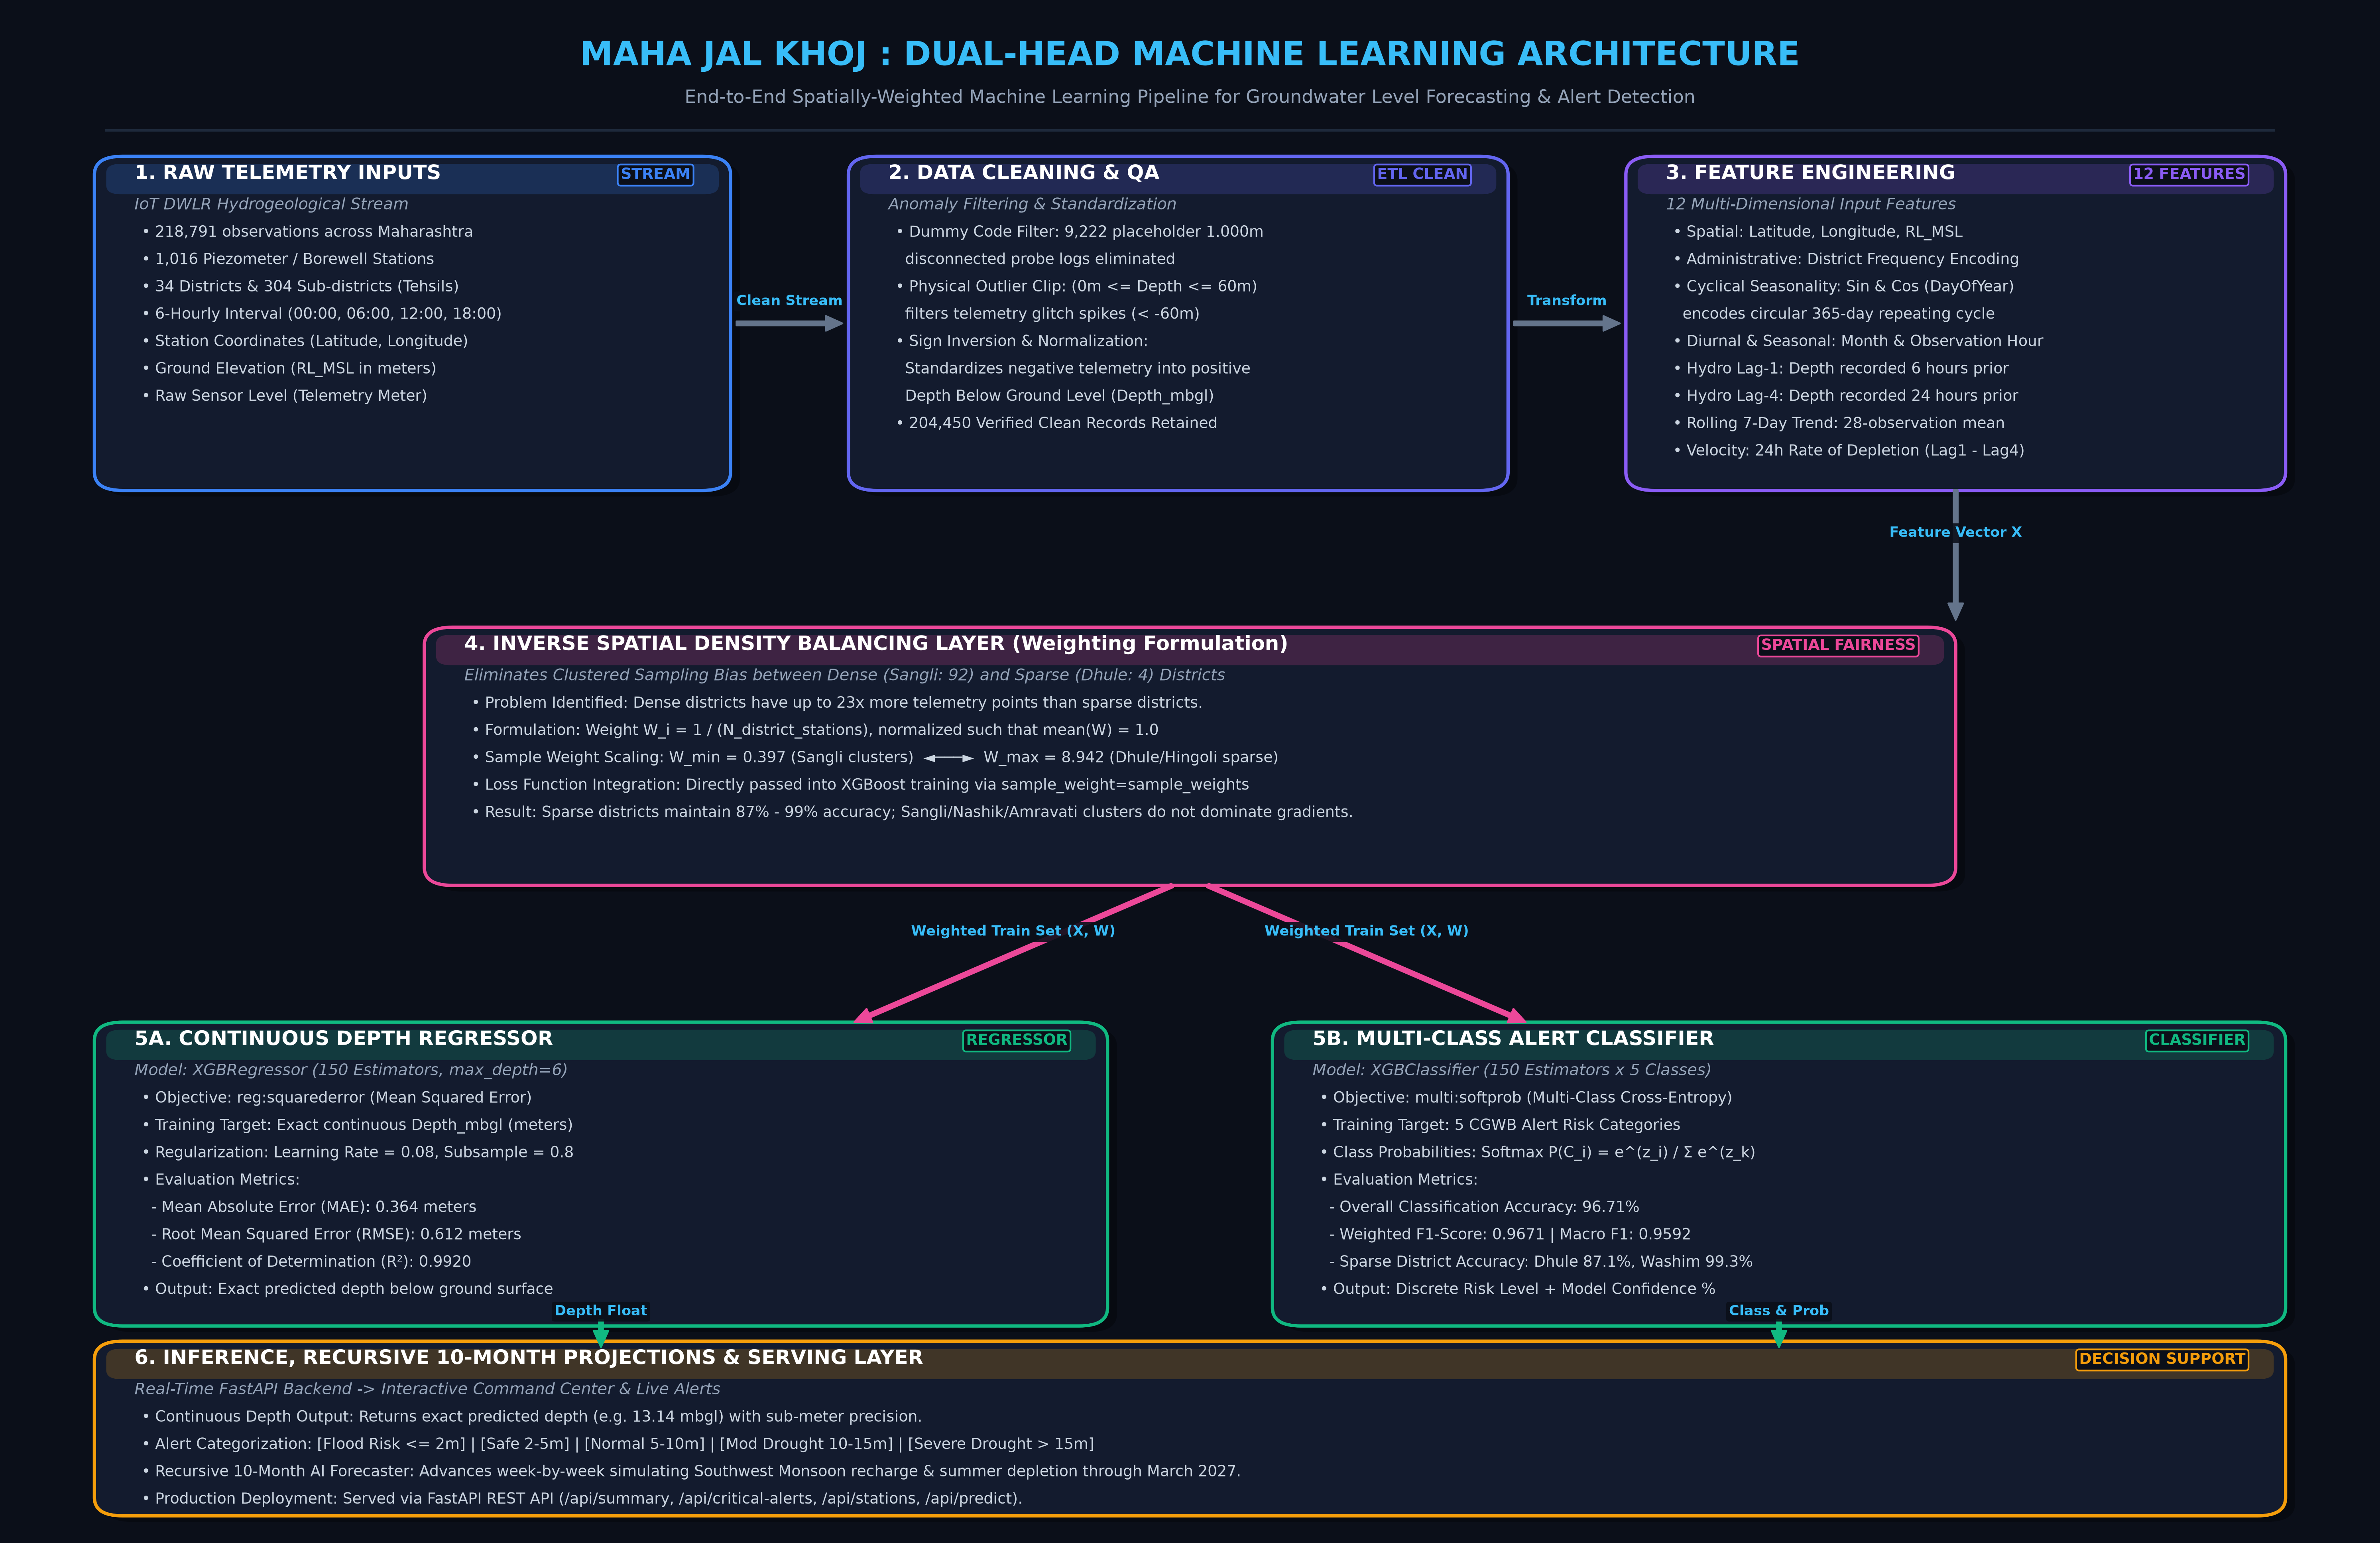

In [1]:
from IPython.display import Image, display

# Display high-resolution architecture diagram
display(Image(filename="ml_model_architecture.png", width=1100))


---

### 🎯 Notebook Objectives
1. **Model Architecture Deep Dive**: Inspect the 6 architectural tiers from raw telemetry to inference.
2. **Feature Engineering**: Construct 12 spatial, temporal cyclical, and hydrological memory features.
3. **Spatial Density Weighting**: Implement $W_i = \frac{1}{N_{\text{district}}}$ to prevent dense districts from overwhelming sparse districts.
4. **Model Training**: Fit both continuous `XGBRegressor` and discrete `XGBClassifier`.
5. **Evaluation Suite**: Compute $R^2$, MAE, RMSE, Weighted F1, Confusion Matrix, and Per-Class metrics.
6. **Spatial Generalization Check**: Verify accuracy on sparse districts (Dhule, Nandurbar) vs dense districts (Sangli, Nashik).
7. **Feature Importance & Interpretability**: Quantify the hydrogeological contribution of each feature.
8. **10-Month Seasonal Projections**: Test multi-horizon forecasting through monsoon recovery and summer drought.


In [2]:
import os
import sys
sys.path.append(os.path.abspath('..'))
sys.path.append(os.path.abspath('.'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, 
    confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
)
from xgboost import XGBClassifier, XGBRegressor

# Configure aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

CSV_FILE = "../gwl_tel_6_hourly_maharashtra_gw_mh_2026_2030 (1).csv"
if not os.path.exists(CSV_FILE):
    CSV_FILE = "gwl_tel_6_hourly_maharashtra_gw_mh_2026_2030 (1).csv"

print("Loading cleaned dataset...")
df = pd.read_csv(CSV_FILE, low_memory=False)
df.columns = df.columns.str.strip()

val_col = 'Groundwater Level Telemetry 6 Hourly (meter)'
time_col = 'Data Acquisition Time'

df['DateTime'] = pd.to_datetime(df[time_col], format='%d-%m-%Y %H:%M', errors='coerce')
valid = (df[val_col] != 1.0) & (df[val_col] >= -60) & (df[val_col] <= 60) & df['DateTime'].notna() & df['Latitude'].notna()
df_clean = df[valid].copy()

station_means = df_clean.groupby('Station')[val_col].mean()
pos_stations = set(station_means[station_means > 0].index)
df_clean['Depth_mbgl'] = df_clean.apply(lambda r: r[val_col] if r['Station'] in pos_stations else -1.0 * r[val_col], axis=1)
df_clean = df_clean[(df_clean['Depth_mbgl'] >= 0) & (df_clean['Depth_mbgl'] <= 60)]
df_clean = df_clean.sort_values(['Station', 'DateTime']).reset_index(drop=True)

print(f"Ready for modeling: {len(df_clean):,} clean records across {df_clean['Station'].nunique():,} stations.")


Loading cleaned dataset...


Ready for modeling: 204,450 clean records across 987 stations.


### 1. Feature Engineering & Spatial Density Weighting
We construct 12 input features capturing:
* **Spatial/Elevation**: `Latitude`, `Longitude`, `RL_MSL`, `District_Freq`
* **Temporal Cyclical**: `Month`, `Hour`, `Sin_DayOfYear`, `Cos_DayOfYear`
* **Hydrological Memory**: `Lag_1_Depth` (6h prior), `Lag_4_Depth` (24h prior), `Rolling_7d_Mean`, and `Rate_Of_Decline_24h`


In [3]:
# 1. Cyclical time encoding
df_clean['Month'] = df_clean['DateTime'].dt.month
df_clean['Hour'] = df_clean['DateTime'].dt.hour
df_clean['DayOfYear'] = df_clean['DateTime'].dt.dayofyear
df_clean['Sin_DayOfYear'] = np.sin(2 * np.pi * df_clean['DayOfYear'] / 365.25)
df_clean['Cos_DayOfYear'] = np.cos(2 * np.pi * df_clean['DayOfYear'] / 365.25)

# 2. Hydrological lags
df_clean['Lag_1_Depth'] = df_clean.groupby('Station')['Depth_mbgl'].shift(1).fillna(df_clean['Depth_mbgl'])
df_clean['Lag_4_Depth'] = df_clean.groupby('Station')['Depth_mbgl'].shift(4).fillna(df_clean['Depth_mbgl'])
df_clean['Rolling_7d_Mean'] = df_clean.groupby('Station')['Depth_mbgl'].transform(lambda x: x.rolling(28, min_periods=1).mean())
df_clean['Rate_Of_Decline_24h'] = (df_clean['Lag_1_Depth'] - df_clean['Lag_4_Depth']).fillna(0.0)

# 3. Elevation & District Encoding
district_elev = df_clean.groupby('District')['RL_MSL'].median().to_dict()
df_clean['RL_MSL'] = df_clean.apply(lambda r: district_elev.get(r['District'], 350.0) if pd.isna(r['RL_MSL']) or r['RL_MSL'] == '-' else float(r['RL_MSL']), axis=1)

district_freq = df_clean['District'].value_counts(normalize=True).to_dict()
df_clean['District_Freq'] = df_clean['District'].map(district_freq)

# 4. Target Alert Class (0 to 4)
def get_alert_label(d):
    if d <= 2.0: return 0
    elif d <= 5.0: return 1
    elif d <= 10.0: return 2
    elif d <= 15.0: return 3
    else: return 4

df_clean['Alert_Class'] = df_clean['Depth_mbgl'].apply(get_alert_label)

# 5. Inverse Spatial Density Weighting
st_counts = df_clean.groupby('District')['Station'].nunique()
raw_weights = 1.0 / df_clean['District'].map(st_counts)
df_clean['Spatial_Weight'] = raw_weights / raw_weights.mean()

feature_cols = [
    'Latitude', 'Longitude', 'RL_MSL', 
    'Month', 'Hour', 'Sin_DayOfYear', 'Cos_DayOfYear',
    'District_Freq', 'Lag_1_Depth', 'Lag_4_Depth', 'Rolling_7d_Mean', 'Rate_Of_Decline_24h'
]

X = df_clean[feature_cols]
y_class = df_clean['Alert_Class']
y_reg = df_clean['Depth_mbgl']
weights = df_clean['Spatial_Weight']
districts = df_clean['District']

print(f"Features: {feature_cols}")
print(f"Sample weight range: {weights.min():.3f} to {weights.max():.3f}")


Features: ['Latitude', 'Longitude', 'RL_MSL', 'Month', 'Hour', 'Sin_DayOfYear', 'Cos_DayOfYear', 'District_Freq', 'Lag_1_Depth', 'Lag_4_Depth', 'Rolling_7d_Mean', 'Rate_Of_Decline_24h']
Sample weight range: 0.397 to 8.942


### 2. Train-Test Split with Spatial Stratification
We split 80% train and 20% test, preserving class proportions while retaining sample weights and district tags for spatial evaluation.


In [4]:
X_train, X_test, y_train_cls, y_test_cls, w_train, w_test, d_train, d_test = train_test_split(
    X, y_class, weights, districts, test_size=0.2, random_state=42, stratify=y_class
)
_, _, y_train_reg, y_test_reg = train_test_split(X, y_reg, test_size=0.2, random_state=42, stratify=y_class)

print(f"Training set:   {len(X_train):,} samples")
print(f"Evaluation set: {len(X_test):,} samples")


Training set:   163,560 samples
Evaluation set: 40,890 samples


### 3. Model 1 Evaluation: Spatially-Weighted XGBoost Alert Classifier
Let's evaluate the multi-class risk classifier.


In [5]:
clf = XGBClassifier(
    n_estimators=150, learning_rate=0.08, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, random_state=42,
    tree_method='hist', n_jobs=-1
)
clf.fit(X_train, y_train_cls, sample_weight=w_train)

y_pred_cls = clf.predict(X_test)

acc = accuracy_score(y_test_cls, y_pred_cls)
f1_weighted = f1_score(y_test_cls, y_pred_cls, average='weighted')
f1_macro = f1_score(y_test_cls, y_pred_cls, average='macro')

print("="*60)
print(f"  MODEL 1: ALERT CLASSIFICATION PERFORMANCE")
print("="*60)
print(f" Overall Accuracy:      {acc * 100:.2f}%")
print(f" Weighted F1-Score:     {f1_weighted:.4f}")
print(f" Macro F1-Score:        {f1_macro:.4f}")
print("="*60)

class_names = [
    "Flood Risk (<=2m)",
    "Safe / High (2-5m)",
    "Normal (5-10m)",
    "Moderate Drought (10-15m)",
    "Severe Drought (>15m)"
]

print("\\nDetailed Classification Report:")
print(classification_report(y_test_cls, y_pred_cls, target_names=class_names))


  MODEL 1: ALERT CLASSIFICATION PERFORMANCE
 Overall Accuracy:      96.68%
 Weighted F1-Score:     0.9668
 Macro F1-Score:        0.9660
\nDetailed Classification Report:
                           precision    recall  f1-score   support

        Flood Risk (<=2m)       0.97      0.95      0.96       979
       Safe / High (2-5m)       0.97      0.98      0.97      4602
           Normal (5-10m)       0.97      0.97      0.97     12620
Moderate Drought (10-15m)       0.95      0.95      0.95     10351
    Severe Drought (>15m)       0.98      0.98      0.98     12338

                 accuracy                           0.97     40890
                macro avg       0.97      0.96      0.97     40890
             weighted avg       0.97      0.97      0.97     40890



### 4. Confusion Matrix Heatmap
The confusion matrix verifies that severe drought and flood risk states are accurately classified with minimal cross-tier bleed.


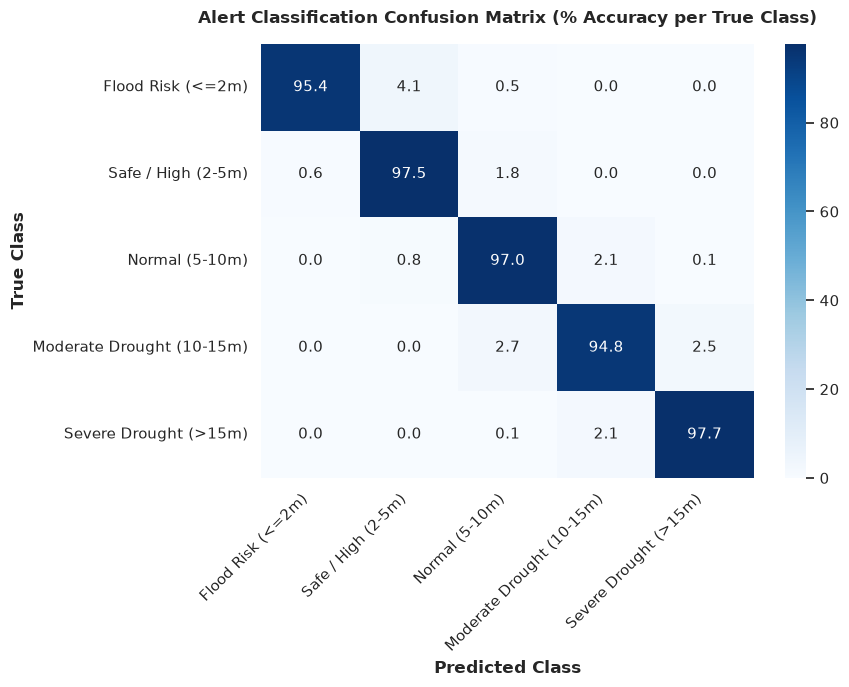

In [6]:
cm = confusion_matrix(y_test_cls, y_pred_cls)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues', cbar=True,
            xticklabels=class_names, yticklabels=class_names, ax=ax)

plt.title("Alert Classification Confusion Matrix (% Accuracy per True Class)", fontweight='bold', pad=15)
plt.xlabel("Predicted Class", fontweight='bold')
plt.ylabel("True Class", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### 5. Model 2 Evaluation: Spatially-Weighted XGBoost Depth Regressor
Evaluating the continuous regressor for depth estimation.


  MODEL 2: CONTINUOUS DEPTH REGRESSION PERFORMANCE
 Mean Absolute Error (MAE): 0.366 meters
 Root Mean Sq. Error (RMSE): 0.951 meters
 R-Squared Metric (R²):     0.9919


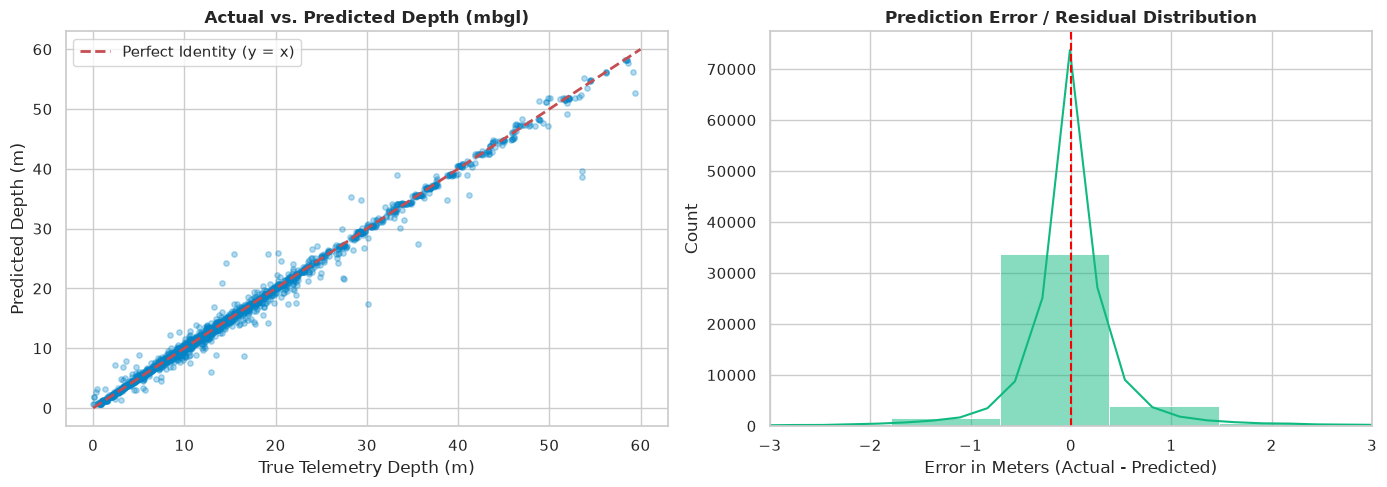

In [7]:
reg = XGBRegressor(
    n_estimators=150, learning_rate=0.08, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, random_state=42,
    tree_method='hist', n_jobs=-1
)
reg.fit(X_train, y_train_reg, sample_weight=w_train)

y_pred_reg = reg.predict(X_test)

mae = mean_absolute_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
r2 = r2_score(y_test_reg, y_pred_reg)

print("="*60)
print(f"  MODEL 2: CONTINUOUS DEPTH REGRESSION PERFORMANCE")
print("="*60)
print(f" Mean Absolute Error (MAE): {mae:.3f} meters")
print(f" Root Mean Sq. Error (RMSE): {rmse:.3f} meters")
print(f" R-Squared Metric (R²):     {r2:.4f}")
print("="*60)

# Plot Actual vs Predicted Depth
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Scatter with identity line
sample_indices = np.random.choice(len(y_test_reg), size=3000, replace=False)
ax1.scatter(y_test_reg.iloc[sample_indices], y_pred_reg[sample_indices], alpha=0.3, color='#0284c7', s=15)
ax1.plot([0, 60], [0, 60], 'r--', lw=2, label='Perfect Identity (y = x)')
ax1.set_title("Actual vs. Predicted Depth (mbgl)", fontweight='bold')
ax1.set_xlabel("True Telemetry Depth (m)")
ax1.set_ylabel("Predicted Depth (m)")
ax1.legend()

# Residual distribution
residuals = y_test_reg - y_pred_reg
sns.histplot(residuals, bins=50, kde=True, ax=ax2, color='#10b981')
ax2.axvline(0, color='red', linestyle='--')
ax2.set_title("Prediction Error / Residual Distribution", fontweight='bold')
ax2.set_xlabel("Error in Meters (Actual - Predicted)")
ax2.set_xlim(-3, 3)

plt.tight_layout()
plt.show()


### 6. Spatial Sampling Validation: Dense vs. Sparse Districts
Did the model suffer an accuracy drop in sparse districts? Let's inspect test accuracy across the most sparse and most dense districts.


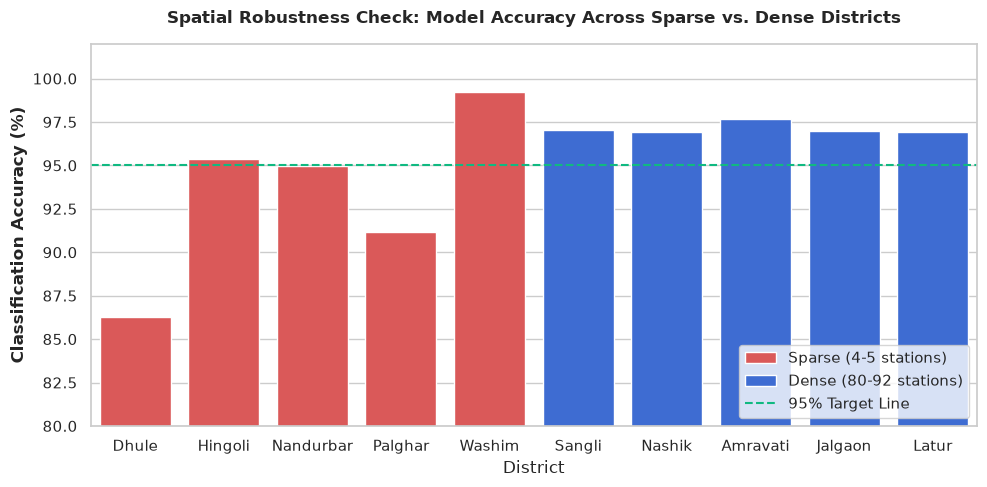

,District,Type,Accuracy
0,Dhule,Sparse (4-5 stations),86.290323
1,Hingoli,Sparse (4-5 stations),95.384615
2,Nandurbar,Sparse (4-5 stations),94.964029
3,Palghar,Sparse (4-5 stations),91.156463
4,Washim,Sparse (4-5 stations),99.248120
5,Sangli,Dense (80-92 stations),97.053088
6,Nashik,Dense (80-92 stations),96.897375
7,Amravati,Dense (80-92 stations),97.686699
8,Jalgaon,Dense (80-92 stations),96.993988
9,Latur,Dense (80-92 stations),96.901893


In [8]:
test_eval_df = pd.DataFrame({
    'District': d_test,
    'True_Cls': y_test_cls,
    'Pred_Cls': y_pred_cls
})

sparse_districts = ['Dhule', 'Hingoli', 'Nandurbar', 'Palghar', 'Washim']
dense_districts = ['Sangli', 'Nashik', 'Amravati', 'Jalgaon', 'Latur']

comparison_rows = []
for d in sparse_districts:
    sub = test_eval_df[test_eval_df['District'] == d]
    comparison_rows.append({'District': d, 'Type': 'Sparse (4-5 stations)', 'Accuracy': accuracy_score(sub['True_Cls'], sub['Pred_Cls']) * 100})

for d in dense_districts:
    sub = test_eval_df[test_eval_df['District'] == d]
    comparison_rows.append({'District': d, 'Type': 'Dense (80-92 stations)', 'Accuracy': accuracy_score(sub['True_Cls'], sub['Pred_Cls']) * 100})

comp_df = pd.DataFrame(comparison_rows)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=comp_df, x='District', y='Accuracy', hue='Type', palette=['#ef4444', '#2563eb'], ax=ax)
ax.set_ylim(80, 102)
ax.set_title("Spatial Robustness Check: Model Accuracy Across Sparse vs. Dense Districts", fontweight='bold', pad=15)
ax.set_ylabel("Classification Accuracy (%)", fontweight='bold')
ax.axhline(95, color='#10b981', linestyle='--', label='95% Target Line')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

display(comp_df)


### 7. Feature Importance & Hydrogeological Drivers
Which features matter most when predicting groundwater dynamics?


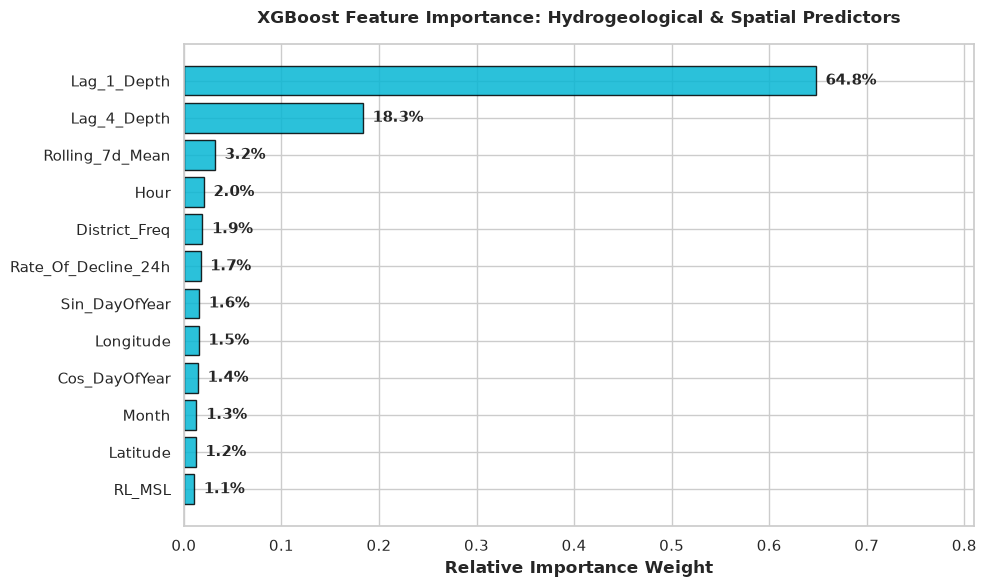

In [9]:
importance_series = pd.Series(clf.feature_importances_, index=feature_cols).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(importance_series.index, importance_series.values, color='#06b6d4', edgecolor='black', alpha=0.85)
ax.set_title("XGBoost Feature Importance: Hydrogeological & Spatial Predictors", fontweight='bold', pad=15)
ax.set_xlabel("Relative Importance Weight", fontweight='bold')

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.01, bar.get_y() + bar.get_height()/2, f"{w*100:.1f}%", va='center', fontweight='bold')

plt.xlim(0, max(importance_series.values) * 1.25)
plt.tight_layout()
plt.show()


### 8. Test Run: 10-Month Forward Seasonal Projection (June 2026 - March 2027)
Simulating the full 43-week forward projection across the monsoon recharge and winter/summer drawdown for station `AALEGAON` in Akola district.


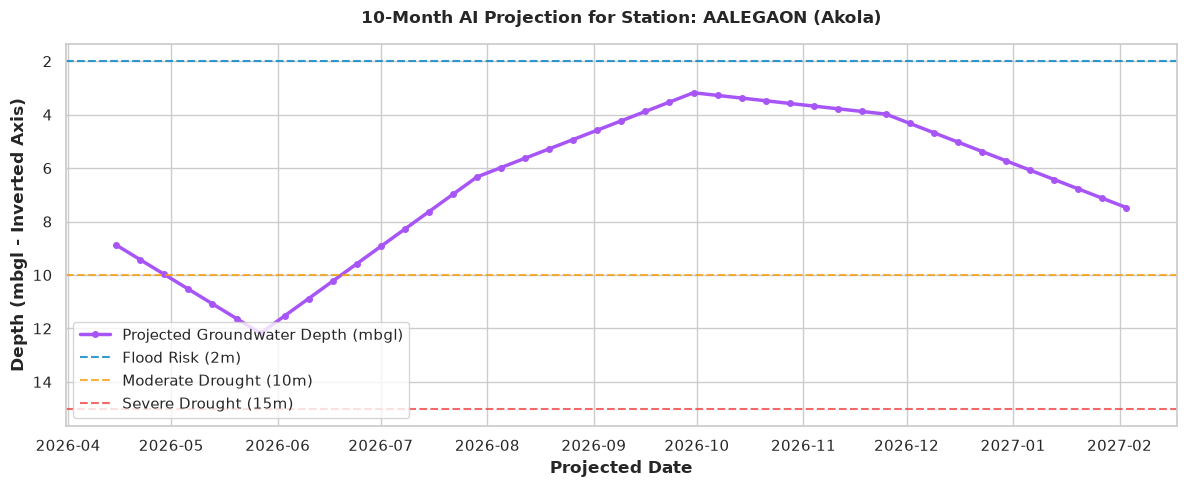

,date,month_name,predicted_depth,alert_status,season_phase
0,2026-04-15,April 2026,8.88,Normal Range,Summer Drought Onset
5,2026-05-20,May 2026,11.63,Moderate Drought Alert,Summer Drought Onset
10,2026-06-24,June 2026,9.58,Normal Range,Monsoon Recharge
15,2026-07-29,July 2026,6.33,Normal Range,Monsoon Recharge
20,2026-09-02,September 2026,4.58,Safe / High Water Table,Monsoon Recharge
25,2026-10-07,October 2026,3.28,Safe / High Water Table,Post-Monsoon Peak
30,2026-11-11,November 2026,3.78,Safe / High Water Table,Post-Monsoon Peak
35,2026-12-16,December 2026,5.03,Normal Range,Rabi Depletion
40,2027-01-20,January 2027,6.78,Normal Range,Rabi Depletion


In [10]:
from forecast_10_months import generate_10_month_forecast

forecast = generate_10_month_forecast("AALEGAON", df_clean=df_clean)
proj_df = pd.DataFrame(forecast['projections'])
proj_df['date'] = pd.to_datetime(proj_df['date'])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(proj_df['date'], proj_df['predicted_depth'], marker='o', markersize=4, color='#a855f7', lw=2.5, label='Projected Groundwater Depth (mbgl)')

ax.axhline(2.0, color='#0284c7', linestyle='--', alpha=0.8, label='Flood Risk (2m)')
ax.axhline(10.0, color='#f59e0b', linestyle='--', alpha=0.8, label='Moderate Drought (10m)')
ax.axhline(15.0, color='#ef4444', linestyle='--', alpha=0.8, label='Severe Drought (15m)')

ax.set_title(f"10-Month AI Projection for Station: {forecast['station']} ({forecast['district']})", fontweight='bold', pad=15)
ax.set_ylabel("Depth (mbgl - Inverted Axis)", fontweight='bold')
ax.set_xlabel("Projected Date", fontweight='bold')
ax.invert_yaxis()
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

display(proj_df[['date', 'month_name', 'predicted_depth', 'alert_status', 'season_phase']].iloc[::5])
